# 03 · The Arduino staircase and the potentiometer model

**Purpose.** Reproduces, sample by sample, the resistance that the Arduino sketches put into the circuit: the tap-by-tap staircase, the straight line through the middle of each step that the analysis uses, and the true versus nominal sweep rate. It answers: what exactly is $R(t)$ during a run, and how do we convert an event time into a resistance?

**In the report.** Chapter 3, Sec. 3.2 (Eq. 3.1, Fig. 3.3, Table 3.1) and Sec. 3.5 (the staircase-to-ramp mapping).

## Theory and protocol

The digital potentiometer has 32 effective taps over its 10 kΩ span, so one step is

$$\Delta R = \frac{10\,\mathrm{k\Omega}}{31} = 322.6\,\Omega . \tag{3.1}$$

Each step is held for $\tau$ (the sketch's `STEP_DELAY_MS`), so the **true** rate is $\lambda = \Delta R/\tau$. The run labels use the nominal rate $312.5\,\Omega/\tau$, which is about 3 % lower.

**Configuration A** (`Rf_sweep_staircase.ino`): after the trigger the loop makes 32 increments, then 32 decrements, each after one $\tau$. Because only 31 steps exist, the top and bottom taps are each held for $2\tau$; the cycle period is $64\tau$.

**Configuration B** (`Ri_sweep_staircase.ino`): the loop starts with 32 decrements while the wiper is already at tap 0, so the first $32\tau$ after the trigger are a hold at the highest gain; then the same up/down pattern follows.

**Staircase to ramp.** The analysis maps time to resistance with the straight line through the middle of every step. For a growth rate linear in the resistance, $\sigma \propto R - R_c$, the integral $\int\sigma\,\mathrm{d}t$ over each step is the same for the staircase and for this line, so the mapping introduces no half-step bias. Section 4 checks this numerically.

## Method

Pure Python models of the two sketches. `tap_of_t` gives the exact tap at any time; `k_lin_of_t` gives the continuous tap number on the mid-step line (flat on the holds). Both are the functions used by notebooks 05, 08, 10 and 12.

## Requirements

Python 3.9+, `numpy`, `pandas`, `matplotlib`.

## Inputs (the only cell to edit)

In [1]:
# ---------------- INPUTS ----------------
CONFIG        = "A"        # "A": R_F swept (Stage 2/3); "B": R_i swept (Stage 4)
STEP_DELAY_MS = 313        # hold per step in the sketch (ms)
POT_SPAN      = 10e3       # ohm
N_TAPS        = 32         # effective taps (31 steps)
STEPS_PER_HALF = 32        # loop count in each half of the sketch's loop()
R_FIXED_A, R_I_A = 91e3, 47e3     # configuration A: R_F = 91 k + pot, R_i = 47 k
R_FIXED_B, R_F_B = 41e3, 90e3     # configuration B: R_i = 41 k + pot, R_F = 90 k
TRIG_WIDTH    = 0.050      # s, trigger pulse width (sweep starts at its falling edge)
N_CYCLES_PLOT = 2
OUT_DIR       = "outputs/03_staircase"

## 1. Step size and rates

In [2]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
os.makedirs(OUT_DIR, exist_ok=True)
STEP_R = POT_SPAN / (N_TAPS - 1)
TOP_TAP = min(STEPS_PER_HALF, N_TAPS - 1)
tau = STEP_DELAY_MS / 1000.0
print(f"true step {STEP_R:.2f} ohm, nominal step {POT_SPAN/32:.1f} ohm")
print(f"tau = {tau*1e3:.0f} ms -> true rate {STEP_R/tau:.1f} ohm/s, nominal label {POT_SPAN/32/tau:.1f} ohm/s "
      f"(ratio {STEP_R/(POT_SPAN/32):.4f})")

true step 322.58 ohm, nominal step 312.5 ohm
tau = 313 ms -> true rate 1030.6 ohm/s, nominal label 998.4 ohm/s (ratio 1.0323)


## 2. The two staircase models

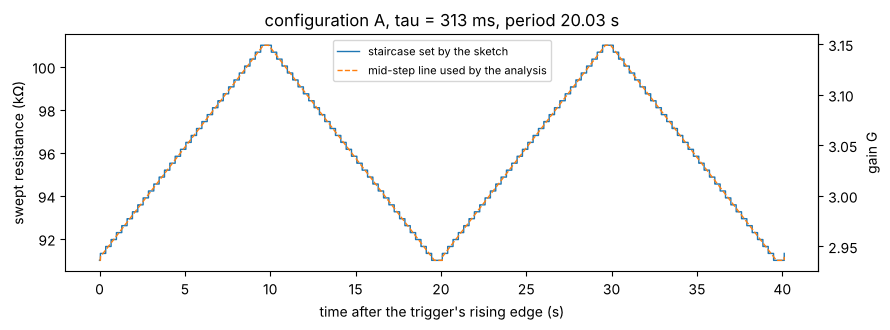

In [3]:
PRE_HOLD = 0 if CONFIG == "A" else STEPS_PER_HALF   # configuration B starts with a 32-step hold

def sweep_u(t, tau):
    # Steps since the first increment (negative during an initial hold) and position u in the 64-step cycle.
    x = (np.asarray(t, float) - (TRIG_WIDTH + PRE_HOLD * tau)) / tau
    return x, np.mod(x, 2 * STEPS_PER_HALF)

def tap_of_t(t, tau):
    # Exact tap set by the sketch at time t (t = 0 at the trigger's rising edge).
    x, u = sweep_u(t, tau)
    up = np.minimum(np.floor(u) + 1, TOP_TAP)
    down = np.maximum(TOP_TAP - 1 - np.floor(u - STEPS_PER_HALF), 0)
    return np.where(x < 0, 0, np.where(u < STEPS_PER_HALF, up, down))

def k_lin_of_t(t, tau):
    # Continuous tap: straight line through the middle of every step, flat on the holds.
    x, u = sweep_u(t, tau)
    k = np.clip(np.minimum(u + 0.5, TOP_TAP + STEPS_PER_HALF - 0.5 - u), 0, TOP_TAP)
    return np.where(x < 0, 0.0, k)

R_fixed = R_FIXED_A if CONFIG == "A" else R_FIXED_B
gain = (lambda R: 1 + R / R_I_A) if CONFIG == "A" else (lambda R: 1 + R_F_B / R)
T = 2 * STEPS_PER_HALF * tau
t = np.linspace(0, TRIG_WIDTH + PRE_HOLD * tau + N_CYCLES_PLOT * T, 20000)
R_stair, R_line = R_fixed + STEP_R * tap_of_t(t, tau), R_fixed + STEP_R * k_lin_of_t(t, tau)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.step(t, R_stair / 1e3, where="post", lw=1, label="staircase set by the sketch")
ax.plot(t, R_line / 1e3, lw=1, ls="--", label="mid-step line used by the analysis")
ax2 = ax.secondary_yaxis("right", functions=(lambda r: gain(r * 1e3), lambda g: g))
ax2.set_ylabel("gain G")
ax.set_xlabel("time after the trigger's rising edge (s)"); ax.set_ylabel(r"swept resistance (k$\Omega$)")
ax.set_title(f"configuration {CONFIG}, tau = {STEP_DELAY_MS} ms, period {T:.2f} s"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, f"staircase_config{CONFIG}.png"), dpi=150); plt.show()

## 3. The rate tables used in the report

In [4]:
delays_A = {100: 3125, 150: 2083, 200: 1562, 250: 1250, 300: 1041, 350: 892, 400: 781, 450: 695, 500: 625,
            750: 417, 1000: 313, 2000: 156, 3000: 104, 4000: 78, 5000: 63, 7500: 42, 9000: 35}
delays_B = [100, 75, 70, 67, 66, 58, 56, 55, 54, 53, 52, 50, 45, 43, 42, 41, 40, 38, 37]
tabA = pd.DataFrame([dict(nominal_rate=n, step_delay_ms=d, true_rate_from_delay=STEP_R / (d / 1000)) for n, d in delays_A.items()])
tabB = pd.DataFrame([dict(step_delay_ms=d, true_rate_from_delay=STEP_R / (d / 1000)) for d in delays_B])
print("Configuration A (the analysis then measures the true step time from each recording):")
print(tabA.round(1).to_string(index=False))
print("\nConfiguration B:"); print(tabB.round(1).to_string(index=False))
tabA.to_csv(os.path.join(OUT_DIR, "rates_configA.csv"), index=False); tabB.to_csv(os.path.join(OUT_DIR, "rates_configB.csv"), index=False)

Configuration A (the analysis then measures the true step time from each recording):
 nominal_rate  step_delay_ms  true_rate_from_delay
          100           3125                 103.2
          150           2083                 154.9
          200           1562                 206.5
          250           1250                 258.1
          300           1041                 309.9
          350            892                 361.6
          400            781                 413.0
          450            695                 464.1
          500            625                 516.1
          750            417                 773.6
         1000            313                1030.6
         2000            156                2067.8
         3000            104                3101.7
         4000             78                4135.6
         5000             63                5120.3
         7500             42                7680.5
         9000             35                9216

## 4. Check: the mid-step line accumulates the same growth as the staircase

Integrate $\sigma \propto (G - G_c)$ over one full cycle, once along the staircase and once along the mid-step line. Over the steps themselves the two integrals are equal when $G$ is linear in the resistance (configuration A); the small remaining difference comes from the half-step ends of the line on the two holds, where the line is flat. For configuration B ($G \propto 1/R_i$) there is in addition a difference of second order in the step.

In [5]:
G_c = 3.0
tt = np.linspace(TRIG_WIDTH + PRE_HOLD * tau, TRIG_WIDTH + PRE_HOLD * tau + T, 400001)
I_stair = np.trapezoid(gain(R_fixed + STEP_R * tap_of_t(tt, tau)) - G_c, tt)
I_line = np.trapezoid(gain(R_fixed + STEP_R * k_lin_of_t(tt, tau)) - G_c, tt)
print(f"integral of (G - G_c) dt over one cycle: staircase {I_stair:.6f} s, mid-step line {I_line:.6f} s, "
      f"relative difference {abs(I_line/I_stair - 1):.1e}")

integral of (G - G_c) dt over one cycle: staircase 0.852426 s, mid-step line 0.852157 s, relative difference 3.1e-04


## Check against the report

In [6]:
checks = {"step 322.6 ohm (Eq. 3.1)": abs(STEP_R - 322.58) < 0.01,
          "nominal 100 ohm/s (3125 ms) is 103.2 ohm/s true": abs(STEP_R / 3.125 - 103.2) < 0.1,
          "true rate about 3.2 % above nominal": abs(STEP_R / 312.5 - 1.032) < 0.001,
          "mid-step line: no half-step bias (configuration A, below 0.1 %)": CONFIG != "A" or abs(I_line / I_stair - 1) < 1e-3}
for k, ok in checks.items(): print(("PASS " if ok else "FAIL ") + k)

PASS step 322.6 ohm (Eq. 3.1)
PASS nominal 100 ohm/s (3125 ms) is 103.2 ohm/s true
PASS true rate about 3.2 % above nominal
PASS mid-step line: no half-step bias (configuration A, below 0.1 %)


## Using your own protocol

Set `STEP_DELAY_MS`, the resistor values and, if your potentiometer differs, `N_TAPS` and `POT_SPAN`. If your loop makes a different number of steps per half, change `STEPS_PER_HALF`. If your sketch has no initial hold, use configuration A's model. The model assumes `delay()` is the only time spent per step; printing to the serial port inside the loop adds time per step.